
# NLP Course : Midterm Assessment

**Student Name:** Tanya Ojha  
**Course:** Applied Natural Language Processing  
**Project:** Comparative Study of Character-Level Language Models

**Objective:** Implement and evaluate Bigram, LSTM, and Transformer language models for next-character prediction using the Tiny Shakespeare dataset.


In [1]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [2]:

import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import time
import urllib.request
import os
import random

# Set random seeds for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("All libraries imported successfully!")
print("Running on:", device)


All libraries imported successfully!
Running on: cuda


## 1. Dataset Description and Exploration

### 1.1 Dataset Selection

For this project, we use the **Tiny Shakespeare dataset**, a small text corpus containing excerpts from the works of William Shakespeare. The dataset consists of dramatic dialogue, character names, punctuation, capitalization, and varied sentence structures.

The dataset is publicly available through Andrej Karpathy's character-level language modeling repository.

**Dataset source:** [Tiny Shakespeare – GitHub](https://github.com/karpathy/char-rnn)

Tiny Shakespeare is suitable for this experiment because it provides a relatively small but linguistically diverse text corpus. Its size makes it computationally manageable while still containing sufficient sequential patterns for language modeling.

We use character-level language modeling rather than word-level language modeling. This allows all three architectures to operate on the same character vocabulary without requiring a complex tokenizer.

The objective is to train three different architectures on the same text corpus and evaluate their ability to predict the next character based on previously observed characters.

The dataset will be downloaded, inspected, and subsequently transformed into numerical representations suitable for model training.

###1.2 Downloading the Dataset

In [3]:

# Create a directory for the dataset
os.makedirs("data", exist_ok=True)

# Define the dataset source
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)

DATA_PATH = "data/tinyshakespeare.txt"

# Download the dataset
urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# Load the text corpus
with open(DATA_PATH, "r", encoding="utf-8") as file:
    text = file.read()

# Display basic information
print("Dataset downloaded successfully!")
print(f"Dataset size: {len(text):,} characters")
print(f"Dataset file: {DATA_PATH}")

print("\nSample from the dataset:\n")
print(text[:1000])


Dataset downloaded successfully!
Dataset size: 1,115,394 characters
Dataset file: data/tinyshakespeare.txt

Sample from the dataset:

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let

###1.3 Dataset Statistics and Character Distribution

We perform an initial exploratory analysis of the Tiny Shakespeare corpus to understand its size and character-level composition.

Since this project focuses on character-level language modeling, the vocabulary consists of all unique characters present in the corpus, including uppercase and lowercase letters, whitespace, digits, and punctuation.

We examine character frequencies to identify the most common symbols and understand the distribution of characters that the models will encounter during training.

This analysis is important because the vocabulary size determines the number of possible output classes for next-character prediction.**bold text**

In [4]:

# Calculate basic dataset statistics
total_characters = len(text)
unique_characters = sorted(set(text))
vocab_size = len(unique_characters)

print("DATASET STATISTICS")
print("-" * 40)
print(f"Total characters: {total_characters:,}")
print(f"Unique characters: {vocab_size}")
print(f"Number of lines: {len(text.splitlines()):,}")
print(f"Vocabulary: {unique_characters}")

# Calculate character frequencies
char_counts = pd.Series(list(text)).value_counts()

print("\nTOP 20 MOST FREQUENT CHARACTERS")
print("-" * 40)
print(char_counts.head(20))


DATASET STATISTICS
----------------------------------------
Total characters: 1,115,394
Unique characters: 65
Number of lines: 40,000
Vocabulary: ['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']

TOP 20 MOST FREQUENT CHARACTERS
----------------------------------------
      169892
e      94611
t      67009
o      65798
a      55507
h      51310
s      49696
r      48889
n      48529
i      45537
\n     40000
l      33339
d      31358
u      26584
m      22243
y      20448
,      19846
w      17585
f      15770
c      15623
Name: count, dtype: int64


### 1.4 Visualization of Character Frequencies
To further understand the corpus, we visualize the frequency distribution of the 20 most common characters.

The visualization helps identify dominant characters, such as whitespace and frequently occurring letters. Character frequency is relevant to language modeling because the model learns probability distributions over the available vocabulary.

The resulting distribution also provides insight into the imbalance between frequently occurring and less frequently occurring characters.

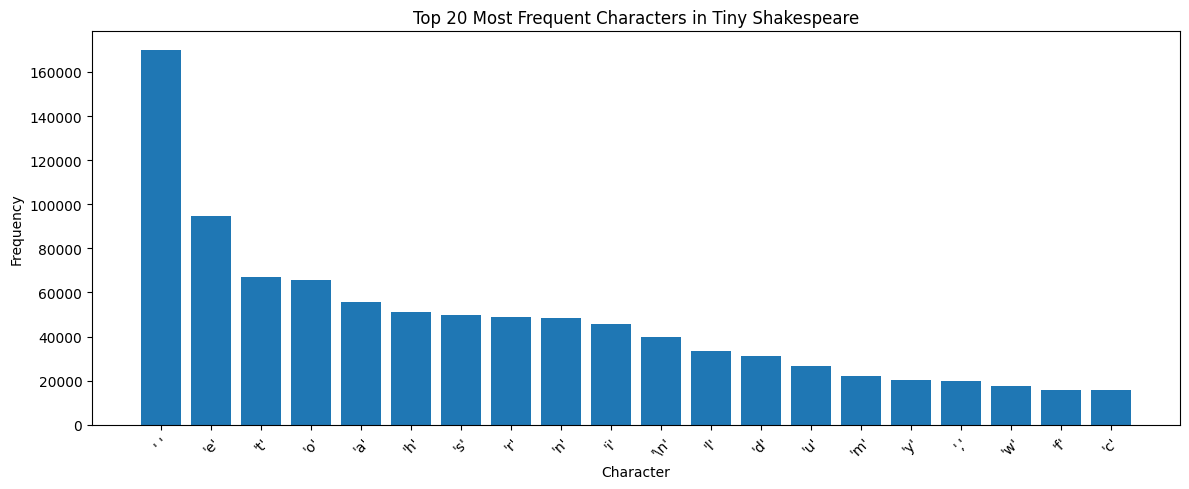

In [5]:

# Select the 20 most frequent characters
top_chars = char_counts.head(20)

# Create readable labels for whitespace characters
labels = [
    repr(char) for char in top_chars.index
]

# Plot character frequencies
plt.figure(figsize=(12, 5))

plt.bar(labels, top_chars.values)

plt.title("Top 20 Most Frequent Characters in Tiny Shakespeare")
plt.xlabel("Character")
plt.ylabel("Frequency")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


### Observations and Findings

The exploratory analysis of the Tiny Shakespeare dataset reveals the following characteristics:

- **Dataset size:** The corpus contains 1,115,394 characters distributed across 40,000 lines.
- **Vocabulary size:** A total of 65 unique characters were identified, including uppercase and lowercase letters, whitespace, punctuation, and numerical characters.
- **Character frequency:** Whitespace is the most frequently occurring character, with 169,892 occurrences, followed by the characters 'e' (94,611), 't' (67,009), and 'o' (65,798).
- **Punctuation and formatting:** The dataset contains punctuation marks, newline characters, and other formatting symbols that contribute to the structure of Shakespearean dialogue.

The frequency distribution demonstrates that character occurrences are not uniform. Common characters appear substantially more frequently than less common characters, resulting in an imbalanced character distribution.

This observation is important for language modeling because the models must learn probability distributions over characters with varying frequencies. The relatively small vocabulary of 65 characters also makes character-level prediction computationally manageable.

The dataset is therefore suitable for comparing statistical, recurrent neural network, and attention-based approaches to next-character prediction.

###1.5 Text Preprocessing and Character Vocabulary

In [6]:

# Extract all unique characters from the dataset
chars = sorted(list(set(text)))

# Calculate the vocabulary size
vocab_size = len(chars)

# Create character-to-integer mapping
stoi = {ch: idx for idx, ch in enumerate(chars)}

# Create integer-to-character mapping
itos = {idx: ch for idx, ch in enumerate(chars)}

# Display vocabulary information
print("CHARACTER VOCABULARY")
print("=" * 50)

print("Vocabulary size:", vocab_size)

print("\nCharacter-to-Integer Mapping:")
for character, index in stoi.items():
    print(f"{repr(character):10} -> {index}")

print("\nInteger-to-Character Mapping:")
for index, character in itos.items():
    print(f"{index:3} -> {repr(character)}")


CHARACTER VOCABULARY
Vocabulary size: 65

Character-to-Integer Mapping:
'\n'       -> 0
' '        -> 1
'!'        -> 2
'$'        -> 3
'&'        -> 4
"'"        -> 5
','        -> 6
'-'        -> 7
'.'        -> 8
'3'        -> 9
':'        -> 10
';'        -> 11
'?'        -> 12
'A'        -> 13
'B'        -> 14
'C'        -> 15
'D'        -> 16
'E'        -> 17
'F'        -> 18
'G'        -> 19
'H'        -> 20
'I'        -> 21
'J'        -> 22
'K'        -> 23
'L'        -> 24
'M'        -> 25
'N'        -> 26
'O'        -> 27
'P'        -> 28
'Q'        -> 29
'R'        -> 30
'S'        -> 31
'T'        -> 32
'U'        -> 33
'V'        -> 34
'W'        -> 35
'X'        -> 36
'Y'        -> 37
'Z'        -> 38
'a'        -> 39
'b'        -> 40
'c'        -> 41
'd'        -> 42
'e'        -> 43
'f'        -> 44
'g'        -> 45
'h'        -> 46
'i'        -> 47
'j'        -> 48
'k'        -> 49
'l'        -> 50
'm'        -> 51
'n'        -> 52
'o'        -> 53
'p'        -> 54
'q'


## 1.6 Encoding and Decoding

### 1.6.1 Motivation

After constructing the character vocabulary, the next step is to convert the textual data into numerical representations that can be processed by the language models.

We implement two operations:

- **Encoding:** Converts each character into its corresponding integer ID using the character-to-integer mapping (`stoi`).
- **Decoding:** Converts a sequence of integer IDs back into readable text using the integer-to-character mapping (`itos`).

These operations allow the models to process numerical inputs while enabling their generated predictions to be converted back into human-readable text.


### 1.6.2 Mathematical Representation

Let the character vocabulary be represented as:

$$
V = \{c_0, c_1, \ldots, c_{64}\}
$$

The encoding function maps each character to an integer:

$$
E(c_i) = i
$$

The decoding function performs the reverse mapping:

$$
D(i) = c_i
$$

For any valid text sequence $x$, the following property should hold:

$$
D(E(x)) = x
$$

This ensures that encoding and decoding preserve the original text without information loss.

### 1.6.3 Verification

The encoding and decoding functions are tested using a sample text. An assertion is used to verify that the decoded output exactly matches the original input.


In [7]:

# Function to encode text into integer IDs
def encode(input_text):
    return [stoi[character] for character in input_text]


# Function to decode integer IDs back into text
def decode(encoded_sequence):
    return ''.join([itos[index] for index in encoded_sequence])


# Test encoding and decoding
sample_text = "Hello Shakespeare!"

encoded_sample = encode(sample_text)
decoded_sample = decode(encoded_sample)

# Display results
print("Original Text:", sample_text)
print("\nEncoded Representation:", encoded_sample)
print("\nDecoded Text:", decoded_sample)

# Verify correctness
assert decoded_sample == sample_text

print("\nEncoding and decoding verification: PASSED")


Original Text: Hello Shakespeare!

Encoded Representation: [20, 43, 50, 50, 53, 1, 31, 46, 39, 49, 43, 57, 54, 43, 39, 56, 43, 2]

Decoded Text: Hello Shakespeare!

Encoding and decoding verification: PASSED



## 1.7 Training and Validation Data Preparation

### 1.7.1 Motivation

After converting the complete text corpus into numerical representations, the next step is to divide the dataset into training and validation subsets.

The training dataset is used to learn the character-level patterns and relationships present in the text. The validation dataset is reserved for evaluating model performance on unseen text.

For this experiment, we use an 80:20 chronological split. The first 80% of the corpus is allocated to training, while the remaining 20% is reserved for validation.

A chronological split ensures that validation characters occur after the training portion of the corpus. This provides a consistent evaluation setting for all three language models.

### 1.7.2 Experimental Data Split

The dataset is divided according to the following proportions:

$$
D = D_{\text{train}} \cup D_{\text{val}}
$$

$$
|D_{\text{train}}| = 0.8|D|
$$

$$
|D_{\text{val}}| = 0.2|D|
$$

The two subsets are non-overlapping, ensuring that the validation portion is not used for model training.

### 1.7.3 Implementation

The encoded corpus is divided into training and validation subsets while preserving the original character order.

The resulting datasets will be shared across the Bigram, LSTM, and Transformer models to maintain consistency during experimental evaluation.


In [8]:

# Convert the complete text corpus into a PyTorch tensor
data = torch.tensor(encode(text), dtype=torch.long)

# Calculate the training split index
split_index = int(0.80 * len(data))

# Perform chronological train-validation split
train_data = data[:split_index]
val_data = data[split_index:]

# Display dataset information
print("TRAINING AND VALIDATION DATA SPLIT")
print("=" * 50)

print(f"Total encoded characters: {len(data):,}")
print(f"Training characters: {len(train_data):,}")
print(f"Validation characters: {len(val_data):,}")

print(f"\nTraining proportion: {len(train_data)/len(data)*100:.2f}%")
print(f"Validation proportion: {len(val_data)/len(data)*100:.2f}%")

# Verify split integrity
assert len(train_data) + len(val_data) == len(data)
assert len(set(train_data.tolist()).intersection(
    set(val_data.tolist())
)) <= vocab_size

print("\nData split verification: PASSED")


TRAINING AND VALIDATION DATA SPLIT
Total encoded characters: 1,115,394
Training characters: 892,315
Validation characters: 223,079

Training proportion: 80.00%
Validation proportion: 20.00%

Data split verification: PASSED



## 1.8 Input-Target Sequence Preparation

### 1.8.1 Context Windows and Next-Character Prediction

Language models learn to predict the next character based on previously observed characters. To train the models, we divide the text into smaller sequences called context windows.

A context window contains a fixed number of consecutive characters that the model uses to predict subsequent characters.

For this experiment, we initially define a context length of 128 characters. This provides the LSTM and Transformer with sufficient preceding context to learn sequential patterns while keeping computation manageable.

### 1.8.2 Input-Target Alignment

Each input sequence is paired with a target sequence shifted forward by one character.

For example, consider the following sequence:

Input: `hello`

Target: `elloo`

At each position, the model predicts the character immediately following the corresponding input character.

Mathematically, for an input sequence:

$$
X = [x_1, x_2, \ldots, x_T]
$$

The corresponding target sequence is:

$$
Y = [x_2, x_3, \ldots, x_{T+1}]
$$

Therefore, each input position has a corresponding next-character prediction target.

### 1.8.3 Batch Preparation

To improve computational efficiency, multiple context windows are grouped into mini-batches.

We initially configure a batch size of 64 and a context length of 128.

Each batch therefore contains 64 input sequences and 64 corresponding target sequences, with 128 character positions per sequence.

The same training and validation data preparation process will be used for the LSTM and Transformer models. The Bigram model will use the same encoded corpus with a one-character context.


In [9]:

# Define sequence preparation parameters
block_size = 128
batch_size = 64

print("SEQUENCE CONFIGURATION")
print("=" * 50)
print("Context length:", block_size)
print("Batch size:", batch_size)


# Function to generate input-target batches
def get_batch(split):

    # Select the appropriate dataset
    source = train_data if split == "train" else val_data

    # Generate random starting positions
    ix = torch.randint(
        len(source) - block_size,
        (batch_size,)
    )

    # Create input sequences
    x = torch.stack([
        source[i:i + block_size] for i in ix
    ])

    # Create targets shifted by one character
    y = torch.stack([
        source[i + 1:i + block_size + 1] for i in ix
    ])

    # Move batches to the selected device
    x = x.to(device)
    y = y.to(device)

    return x, y


# Generate sample training and validation batches
x_train, y_train = get_batch("train")
x_val, y_val = get_batch("val")


# Display batch information
print("\nTRAINING BATCH")
print("Input shape:", x_train.shape)
print("Target shape:", y_train.shape)

print("\nVALIDATION BATCH")
print("Input shape:", x_val.shape)
print("Target shape:", y_val.shape)


# Verify sequence alignment
assert x_train.shape == (batch_size, block_size)
assert y_train.shape == (batch_size, block_size)

assert torch.equal(x_train[:, 1:], y_train[:, :-1])

print("\nInput-target alignment verification: PASSED")


SEQUENCE CONFIGURATION
Context length: 128
Batch size: 64

TRAINING BATCH
Input shape: torch.Size([64, 128])
Target shape: torch.Size([64, 128])

VALIDATION BATCH
Input shape: torch.Size([64, 128])
Target shape: torch.Size([64, 128])

Input-target alignment verification: PASSED



### 1.9 Batch Generation and Verification

To verify the data preparation pipeline, we inspect an individual input sequence and its corresponding target sequence.

The encoded sequences are decoded back into readable characters to confirm that the target sequence is shifted forward by exactly one character relative to the input sequence.

This verification ensures that the model receives correctly aligned training examples and learns the intended next-character prediction task.

The same sequence preparation pipeline will be used throughout the neural language modeling experiments.


In [10]:

# Select one sample from the training batch
sample_input = x_train[0].tolist()
sample_target = y_train[0].tolist()

# Decode the numerical sequences
decoded_input = decode(sample_input)
decoded_target = decode(sample_target)

# Display a short portion of the sequences
print("INPUT SEQUENCE (first 50 characters):")
print(repr(decoded_input[:50]))

print("\nTARGET SEQUENCE (first 50 characters):")
print(repr(decoded_target[:50]))

# Verify next-character alignment
print("\nFirst 10 input-target character pairs:")

for i in range(10):
    print(
        f"Input: {repr(decoded_input[i])} "
        f"-> Target: {repr(decoded_target[i])}"
    )

assert decoded_target[:-1] == decoded_input[1:]

print("\nBatch verification: PASSED")


INPUT SEQUENCE (first 50 characters):
'all be charged again. Whiles we have struck,\nBy in'

TARGET SEQUENCE (first 50 characters):
'll be charged again. Whiles we have struck,\nBy int'

First 10 input-target character pairs:
Input: 'a' -> Target: 'l'
Input: 'l' -> Target: 'l'
Input: 'l' -> Target: ' '
Input: ' ' -> Target: 'b'
Input: 'b' -> Target: 'e'
Input: 'e' -> Target: ' '
Input: ' ' -> Target: 'c'
Input: 'c' -> Target: 'h'
Input: 'h' -> Target: 'a'
Input: 'a' -> Target: 'r'

Batch verification: PASSED



# Part 2 — Model 1: Bigram Language Model

## 2.1 Introduction and Theoretical Background

A Bigram Language Model is a statistical language model that predicts the next character based exclusively on the immediately preceding character.

Unlike neural language models, a basic Bigram model does not maintain a hidden state or use attention mechanisms. Instead, it learns the statistical relationships between consecutive characters by estimating conditional probabilities from the training corpus.

In this project, the Bigram model serves as a baseline against which the more complex LSTM and Transformer architectures will be compared.

### 2.1.1 Conditional Probability

The Bigram model estimates the probability of a character occurring given the character immediately before it.

This is represented as:

$$
P(x_t \mid x_{t-1})
$$

where:

- $x_t$ represents the current character being predicted.
- $x_{t-1}$ represents the preceding character.

The model uses the following conditional probability:

$$
P(x_t \mid x_{t-1})
=
\frac{C(x_{t-1},x_t)}{C(x_{t-1})}
$$

where:

- $C(x_{t-1},x_t)$ is the number of times the character pair occurs in the training corpus.
- $C(x_{t-1})$ is the total number of occurrences of the preceding character.

### 2.1.2 Markov Assumption

The Bigram model follows a first-order Markov assumption.

It assumes that the next character depends only on the immediately preceding character rather than the entire sequence of previously observed characters.

Mathematically:

$$
P(x_t \mid x_1,\ldots,x_{t-1})
\approx
P(x_t \mid x_{t-1})
$$

This simplifies language modeling but introduces an important limitation: the model cannot directly capture long-range dependencies or relationships between distant characters.

### 2.1.3 Limitations of the Bigram Model

Although computationally simple, the Bigram model has several limitations:

1. It considers only one preceding character.
2. It cannot capture long-range linguistic dependencies.
3. It does not maintain contextual representations of the sequence.
4. It may generate locally plausible character combinations without producing coherent words or sentences.

These limitations provide motivation for exploring recurrent neural networks and attention-based architectures in the subsequent sections.



## 2.2 Bigram Model Architecture and Working Principle

The Bigram Language Model learns the relationships between consecutive characters by constructing a character transition probability matrix from the training dataset.

Since our vocabulary contains 65 unique characters, the model uses a 65 × 65 matrix to represent the transition probabilities between all possible character pairs.

### 2.2.1 Bigram Frequency Matrix

The first step is to count how frequently each character is followed by another character in the training corpus.

Let $C(i,j)$ represent the number of times character $j$ immediately follows character $i$.

The frequency matrix is defined as:

$$
C(i,j) = \text{Count}(x_{t-1}=i,\ x_t=j)
$$

Each row represents the preceding character, while each column represents the next character.

For our vocabulary of 65 characters, the resulting matrix has the dimensions:

$$
C \in \mathbb{R}^{65 \times 65}
$$

### 2.2.2 Transition Probability Matrix

After calculating character-pair frequencies, we normalize each row to obtain conditional probabilities.

The transition probability from character $i$ to character $j$ is:

$$
P(j \mid i) =
\frac{C(i,j)}{\sum_{k=0}^{64} C(i,k)}
$$

Each row therefore represents a probability distribution over the possible next characters.

The sum of probabilities in each non-empty row should equal 1:

$$
\sum_{j=0}^{64} P(j \mid i) = 1
$$

### 2.2.3 Prediction Mechanism

When the model receives a character, it identifies the corresponding row in the transition probability matrix.

It then uses this probability distribution to predict the next character.

For example, given the current character 'q', the model may assign a high probability to 'u' because these characters frequently occur consecutively in English text.

The next character can be selected either by choosing the most probable character or by sampling from the learned probability distribution.

In this project, we use probability-based sampling during text generation to produce varied outputs.

### 2.2.4 Architectural Characteristics

The Bigram model is fundamentally different from the neural architectures introduced later:

- It uses character-pair frequency counts instead of learned neural representations.
- It maintains no hidden states or memory of earlier characters.
- It uses a single-character context for every prediction.
- Its probability matrix directly represents the learned character transitions.

The model provides a computationally inexpensive baseline for evaluating how much improvement can be obtained by introducing longer contextual representations through LSTM and Transformer architectures.



## 2.3 Bigram Model Implementation

### 2.3.1 Constructing the Bigram Frequency Matrix

The Bigram model is implemented using a frequency matrix that records how often each character is followed by another character in the training corpus.

Since the vocabulary contains 65 unique characters, we initialize a 65 × 65 matrix of zeros.

For every consecutive character pair in the training dataset, the corresponding matrix entry is incremented.

The frequency matrix is constructed using the encoded training sequence. Each row represents the preceding character, and each column represents the following character.

### 2.3.2 Laplace Smoothing

To handle character pairs that do not occur in the training corpus, we apply Laplace smoothing with a smoothing parameter of $\alpha = 1$.

The smoothed conditional probability is calculated as:

$$
P(j \mid i) =
\frac{C(i,j)+\alpha}
{\sum_{k=0}^{64} C(i,k)+\alpha V}
$$

where $V$ represents the vocabulary size.

Laplace smoothing ensures that every possible character transition receives a non-zero probability, including transitions that were not observed during training.

### 2.3.3 Probability Matrix Construction

After smoothing, each row of the frequency matrix is normalized to obtain a probability distribution over possible next characters.

The resulting matrix is used for next-character prediction and autoregressive text generation.


In [11]:

# Start measuring Bigram model construction time
bigram_start_time = time.time()

# Initialize the Bigram frequency matrix
bigram_counts = torch.zeros(
    (vocab_size, vocab_size),
    dtype=torch.float32
)

# Extract consecutive character pairs from training data
input_chars = train_data[:-1]
target_chars = train_data[1:]

# Convert character pairs into flattened matrix indices
pair_indices = input_chars * vocab_size + target_chars

# Count all character transitions efficiently
bigram_counts = torch.bincount(
    pair_indices,
    minlength=vocab_size * vocab_size
).reshape(vocab_size, vocab_size).float()

# Apply Laplace smoothing
alpha = 1.0

smoothed_counts = bigram_counts + alpha

# Normalize each row to obtain transition probabilities
bigram_probs = smoothed_counts / smoothed_counts.sum(
    dim=1,
    keepdim=True
)

# Measure construction time
bigram_construction_time = time.time() - bigram_start_time

# Display model information
print("BIGRAM MODEL IMPLEMENTATION")
print("=" * 50)

print("Vocabulary size:", vocab_size)
print("Frequency matrix shape:", bigram_counts.shape)
print("Probability matrix shape:", bigram_probs.shape)
print("Smoothing parameter:", alpha)

print("\nObserved character transitions:",
      int(bigram_counts.sum().item()))

print("Total possible character transitions:",
      vocab_size * vocab_size)

print("Model construction time:",
      f"{bigram_construction_time:.4f} seconds")

# Verify probability matrix
row_sums = bigram_probs.sum(dim=1)

print("\nPROBABILITY MATRIX VERIFICATION")
print("=" * 50)

print("Minimum row sum:", row_sums.min().item())
print("Maximum row sum:", row_sums.max().item())
print("Minimum probability:", bigram_probs.min().item())

assert bigram_probs.shape == (vocab_size, vocab_size)
assert torch.allclose(
    row_sums,
    torch.ones(vocab_size),
    atol=1e-6
)

assert torch.all(bigram_probs > 0)

print("\nBigram probability verification: PASSED")


BIGRAM MODEL IMPLEMENTATION
Vocabulary size: 65
Frequency matrix shape: torch.Size([65, 65])
Probability matrix shape: torch.Size([65, 65])
Smoothing parameter: 1.0

Observed character transitions: 892314
Total possible character transitions: 4225
Model construction time: 0.1043 seconds

PROBABILITY MATRIX VERIFICATION
Minimum row sum: 0.9999998211860657
Maximum row sum: 1.0000001192092896
Minimum probability: 7.33971910449327e-06

Bigram probability verification: PASSED


###2.3.4 Inspecting Learned Character Transitions

In [12]:

# Select a character to inspect
current_char = 'q'

# Retrieve its vocabulary index
current_idx = stoi[current_char]

# Obtain the learned probability distribution
next_char_probs = bigram_probs[current_idx]

# Identify the five most probable next characters
top_probabilities, top_indices = torch.topk(
    next_char_probs,
    k=5
)

print(f"Most probable characters following '{current_char}':")
print("-" * 45)

for probability, index in zip(
    top_probabilities.tolist(),
    top_indices.tolist()
):
    print(
        f"Next character: {repr(itos[index])} | "
        f"Probability: {probability:.4f}"
    )


Most probable characters following 'q':
---------------------------------------------
Next character: 'u' | Probability: 0.8889
Next character: 'd' | Probability: 0.0017
Next character: 'e' | Probability: 0.0017
Next character: 'f' | Probability: 0.0017
Next character: 'c' | Probability: 0.0017



## 2.4 Model Training and Loss Evaluation

### 2.4.1 Evaluation Objective

Unlike neural language models, the Bigram model does not require iterative gradient-based optimization. Its parameters are estimated directly from character-pair frequencies in the training corpus.

After constructing the transition probability matrix, we evaluate the model's next-character prediction performance using cross-entropy loss.

We calculate the loss separately on the training and validation datasets to assess how well the model learns observed character transitions and generalizes to unseen text.

### 2.4.2 Cross-Entropy Loss

Cross-entropy measures the difference between the predicted probability distribution and the actual next character.

For a single character prediction, the loss is:

$$
L = -\log P(x_t \mid x_{t-1})
$$

For a dataset containing $N$ character transitions, the average cross-entropy loss is:

$$
L = -\frac{1}{N}
\sum_{t=1}^{N}
\log P(x_t \mid x_{t-1})
$$

A lower cross-entropy loss indicates that the model assigns higher probabilities to the actual next characters.

### 2.4.3 Training and Validation Evaluation

The Bigram probability matrix is learned exclusively from the training dataset.

We evaluate the model using:

- Training loss: Measures prediction performance on character transitions from the training corpus.
- Validation loss: Measures prediction performance on character transitions from the held-out validation corpus.

Both losses are calculated using the same probability matrix and evaluation procedure.

Since the Bigram model is count-based, its training consists of estimating transition probabilities rather than repeatedly updating neural network parameters through epochs.


In [13]:

# Function to calculate Bigram cross-entropy loss
def calculate_bigram_loss(encoded_data, probability_matrix):

    # Extract consecutive input-target character pairs
    inputs = encoded_data[:-1]
    targets = encoded_data[1:]

    # Retrieve the probability assigned to each actual next character
    probabilities = probability_matrix[inputs, targets]

    # Calculate average negative log-likelihood
    loss = -torch.log(probabilities).mean()

    return loss.item()


# Evaluate training performance
bigram_train_loss = calculate_bigram_loss(
    train_data,
    bigram_probs
)

# Evaluate validation performance
bigram_val_loss = calculate_bigram_loss(
    val_data,
    bigram_probs
)


# Display evaluation results
print("BIGRAM MODEL EVALUATION")
print("=" * 50)

print(f"Training Loss:   {bigram_train_loss:.4f}")
print(f"Validation Loss: {bigram_val_loss:.4f}")

print("\nPERPLEXITY")
print("=" * 50)

print(f"Training Perplexity:   {np.exp(bigram_train_loss):.4f}")
print(f"Validation Perplexity: {np.exp(bigram_val_loss):.4f}")

# Store results for final comparison
bigram_results = {
    "Model": "Bigram",
    "Train Loss": bigram_train_loss,
    "Validation Loss": bigram_val_loss,
    "Training Time": bigram_construction_time
}

print("\nEvaluation completed successfully.")


BIGRAM MODEL EVALUATION
Training Loss:   2.4515
Validation Loss: 2.4996

PERPLEXITY
Training Perplexity:   11.6054
Validation Perplexity: 12.1780

Evaluation completed successfully.



## 2.5 Text Generation

### 2.5.1 Autoregressive Text Generation

After evaluating the Bigram model, we use its learned transition probabilities to generate new text.

The generation process is autoregressive, meaning that each newly generated character becomes the input for predicting the subsequent character.

The process begins with an initial character. The model retrieves the corresponding probability distribution from the Bigram transition matrix and samples the next character.

This process is repeated until the desired sequence length is reached.

### 2.5.2 Sampling Strategy

At each generation step, the model samples the next character from the conditional probability distribution:

$$
x_t \sim P(x_t \mid x_{t-1})
$$

The sampled character is appended to the existing sequence and used to generate the next character.

Unlike greedy decoding, which always selects the most probable character, probabilistic sampling introduces variation into the generated output.

This allows us to examine the language patterns learned by the model rather than repeatedly generating the same deterministic sequence.


In [14]:

# Function to generate text using the Bigram model
def generate_bigram(start_text, max_new_tokens=500):

    # Encode the starting text
    context = encode(start_text)

    # Convert context into a tensor
    context = torch.tensor(context, dtype=torch.long)

    # Generate characters autoregressively
    for _ in range(max_new_tokens):

        # Get the most recent character
        current_idx = context[-1]

        # Retrieve next-character probabilities
        probabilities = bigram_probs[current_idx]

        # Sample the next character
        next_idx = torch.multinomial(
            probabilities,
            num_samples=1
        )

        # Append the predicted character
        context = torch.cat((context, next_idx))

    # Decode the complete sequence
    return decode(context.tolist())


# Generate Shakespeare-style text
bigram_sample = generate_bigram(
    start_text="ROMEO:",
    max_new_tokens=500
)

print("BIGRAM MODEL — GENERATED TEXT")
print("=" * 60)
print(bigram_sample)


BIGRAM MODEL — GENERATED TEXT
ROMEO:

EROMyot we wed wone'shit se,

I w
LEorouseag

ILENICouso d:
Angrins drese ks le unomy lay omaler cy; mardralv wf t f d Inodof f owe, ofous misearars choblyshoroowe w ivimorear g athil indis the, ced thistterieritovave pat?
OMary ouminvee s s our ofargle, tabes ro t trwe kicary nows t courefome!
K:
Wer ey swit d, s this LARLENRORI y wher ban ganthe th ilistr ntt's ss s uce.
That:
Boure e eke! d k t raghedo ve ICince t in s.
An hedulk jurdyosh'e,
S:
Byond s,

CAghis evou he why m t te,-d ino g w



## 2.6 Results and Observations

### 2.6.1 Experimental Results

The Bigram Language Model was successfully implemented using a character transition probability matrix with Laplace smoothing.

The model was evaluated using cross-entropy loss on both training and validation datasets. Its ability to generate Shakespeare-style text was also examined.

The experimental results are summarized below:

| Evaluation Metric | Result |
|---|---:|
| Vocabulary Size | 65 |
| Training Loss | 2.4515 |
| Validation Loss | 2.4996 |
| Training Perplexity | 11.6054 |
| Validation Perplexity | 12.1780 |
| Model Construction Time | 0.1043 seconds |

### 2.6.2 Analysis of Generated Text

The generated text demonstrates that the Bigram model learns local character-level patterns from the Shakespeare corpus.

The output contains recognizable character combinations, occasional English words, punctuation, and dialogue-like formatting. However, the generated sentences frequently lack grammatical structure and meaningful coherence.

Although the model can reproduce locally plausible character transitions, it cannot maintain consistent sentence-level context because each prediction depends exclusively on the immediately preceding character.

This limitation is particularly noticeable when examining longer generated sequences, where recognizable words and punctuation appear alongside nonsensical character combinations.

### 2.6.3 Model Strengths and Limitations

**Strengths:**

- Simple and computationally inexpensive implementation.
- Fast construction using character transition frequencies.
- Learns common local character patterns effectively.
- Provides a useful statistical baseline for language modeling.

**Limitations:**

- Uses only one preceding character for prediction.
- Cannot capture long-range dependencies.
- Does not maintain contextual information across sequences.
- Produces text with limited grammatical and semantic coherence.

### 2.6.4 Overall Observation

The Bigram model establishes a baseline for character-level next-token prediction. Its low computational complexity allows it to learn local character relationships efficiently. However, its restricted context limits its ability to capture broader linguistic structures.

These findings motivate the use of recurrent neural networks, which can maintain information across sequential inputs and potentially capture more complex dependencies.



# Part 3 — Model 2: LSTM Language Model

## 3.1 Introduction and Theoretical Background

Long Short-Term Memory (LSTM) is a recurrent neural network architecture designed to learn dependencies in sequential data. Unlike the Bigram model, which considers only the previous character, an LSTM maintains internal memory to capture patterns across longer sequences.

### 3.1.1 Recurrent Neural Networks

An RNN processes sequences one element at a time, updating its hidden state using the current input and previous hidden state:

$$
h_t=f(W_{xh}x_t+W_{hh}h_{t-1}+b_h)
$$

where $x_t$ is the current input, $h_t$ is the hidden state, and $W$ and $b_h$ are learned parameters. Standard RNNs can struggle with long-term dependencies due to vanishing gradients.

### 3.1.2 Long Short-Term Memory

LSTMs address this limitation through a memory cell and three gates:

- **Forget gate:** Removes unnecessary information.
- **Input gate:** Controls what new information is stored.
- **Output gate:** Determines the information passed to the next hidden state.

These gates regulate information flow, helping the network retain relevant information across time steps.

### 3.1.3 LSTM for Character-Level Language Modeling

In this experiment, character sequences from Tiny Shakespeare are converted into embeddings and processed by a two-layer LSTM. A linear output layer predicts a probability distribution over the 65-character vocabulary at each position.

The model learns to predict the next character using information accumulated through its hidden and cell states.

### 3.1.4 Advantages and Limitations

**Advantages:**
- Captures sequential dependencies across multiple characters.
- Retains information through memory cells.
- Learns more complex patterns than Bigram models.

**Limitations:**
- Sequential processing limits parallelization.
- Can struggle with very long-range dependencies.
- Requires more computation than statistical models.

The LSTM serves as an intermediate architecture for evaluating how recurrent memory improves next-character prediction before introducing the Transformer's self-attention mechanism.



## 3.2 LSTM Architecture and Working Principle

The LSTM language model is implemented using an embedding layer, a recurrent LSTM layer, and a fully connected output layer.

### 3.2.1 Embedding Layer

The input characters are represented as integer IDs from the shared vocabulary.

An embedding layer maps each integer ID into a dense numerical vector of a predefined dimension.

This allows the network to learn representations of characters during training rather than operating directly on integer identifiers.

### 3.2.2 LSTM Layer

The embedded character sequences are processed by the LSTM layer.

At each time step, the LSTM updates its hidden state and cell state using its forget, input, and output gates.

The resulting hidden representations capture information accumulated from the preceding characters.

### 3.2.3 Fully Connected Output Layer

The hidden representations are passed through a linear layer that maps them to the vocabulary size.

Since our vocabulary contains 65 characters, the output layer produces 65 scores for every input position.

These scores, known as logits, represent the model's predictions over the possible next characters.

### 3.2.4 Forward Propagation

The overall architecture follows this sequence:

$$
X \rightarrow Embedding \rightarrow LSTM
$$

$$
LSTM \rightarrow Linear \rightarrow Logits
$$

The predicted character probabilities are obtained by applying softmax to the output logits:

$$
P(x_t=j) = \frac{e^{z_j}}{\sum_{k=0}^{64}e^{z_k}}
$$

where $z_j$ represents the output logit corresponding to character $j$.

The model is trained by minimizing cross-entropy loss between its predicted logits and the actual next-character targets.



## 3.3 LSTM Model Implementation

### 3.3.1 Model Architecture

The LSTM language model is implemented using PyTorch's `nn.Module`. It consists of three primary components:

1. **Embedding Layer:** Converts character IDs into dense numerical vectors of dimension 128.
2. **LSTM Layer:** Processes the embedded sequences and maintains hidden and cell states to capture sequential dependencies.
3. **Fully Connected Output Layer:** Maps the LSTM hidden representations to 65 output classes corresponding to the character vocabulary.

The model produces next-character predictions at every position in the input sequence.

### 3.3.2 Hyperparameter Configuration

The initial model configuration is:

| Hyperparameter | Value |
|---|---:|
| Vocabulary size | 65 |
| Embedding dimension | 128 |
| Hidden dimension | 256 |
| Number of LSTM layers | 2 |
| Dropout | 0.2 |
| Batch size | 64 |
| Context length | 128 |

These hyperparameters define a relatively small recurrent neural network suitable for training on the available Google Colab GPU.

### 3.3.3 Forward Propagation

During forward propagation, the input character IDs are first converted into embeddings. The resulting representations are passed through the LSTM, which produces hidden representations at each sequence position.

A fully connected layer transforms these representations into vocabulary-sized logits.

The overall computation is:

$$
X \rightarrow Embedding \rightarrow LSTM \rightarrow Linear
$$

The resulting output tensor contains 65 prediction scores for every character position in each input sequence.

### 3.3.4 Forward Pass Verification

Before training, we verify that the model accepts the prepared input batches and produces outputs with the expected dimensions.

For a batch size of 64, context length of 128, and vocabulary size of 65, the expected output shape is:

$$
(B,T,V) = (64,128,65)
$$

This confirms that the model produces a prediction distribution over the complete character vocabulary at every input position.


In [15]:

# ==========================================
# 3.3 LSTM MODEL IMPLEMENTATION
# ==========================================

# Hyperparameter configuration
embedding_dim = 128
hidden_dim = 256
num_layers = 2
dropout_rate = 0.2


# Define LSTM Language Model
class LSTMLanguageModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_layers,
        dropout_rate
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout_rate
        )

        self.fc = nn.Linear(
            hidden_dim,
            vocab_size
        )

    def forward(self, x, hidden=None):

        embedded = self.embedding(x)

        output, hidden = self.lstm(
            embedded,
            hidden
        )

        logits = self.fc(output)

        return logits, hidden


# Initialize model
lstm_model = LSTMLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    num_layers=num_layers,
    dropout_rate=dropout_rate
).to(device)


# Display architecture
print("LSTM LANGUAGE MODEL")
print("=" * 50)

print(lstm_model)


# Calculate trainable parameters
total_parameters = sum(
    p.numel()
    for p in lstm_model.parameters()
    if p.requires_grad
)

print("\nTotal trainable parameters:", f"{total_parameters:,}")


# ==========================================
# FORWARD PASS VERIFICATION
# ==========================================

sample_x, sample_y = get_batch("train")

lstm_model.eval()

with torch.no_grad():
    logits, hidden_state = lstm_model(sample_x)

print("\nLSTM FORWARD PASS VERIFICATION")
print("=" * 50)

print("Input shape:", sample_x.shape)
print("Target shape:", sample_y.shape)
print("Output logits shape:", logits.shape)

expected_shape = (
    batch_size,
    block_size,
    vocab_size
)

print("Expected output shape:", expected_shape)

assert logits.shape == expected_shape

print("\nForward pass verification: PASSED")


LSTM LANGUAGE MODEL
LSTMLanguageModel(
  (embedding): Embedding(65, 128)
  (lstm): LSTM(128, 256, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=256, out_features=65, bias=True)
)

Total trainable parameters: 946,625

LSTM FORWARD PASS VERIFICATION
Input shape: torch.Size([64, 128])
Target shape: torch.Size([64, 128])
Output logits shape: torch.Size([64, 128, 65])
Expected output shape: (64, 128, 65)

Forward pass verification: PASSED



## 3.4 LSTM Model Training and Loss Evaluation

### 3.4.1 Training Objective

The LSTM is trained to predict the next character at every position in an input sequence.

During training, the model receives batches of encoded character sequences and produces vocabulary-sized logits for each position. These predictions are compared with the corresponding next-character targets using categorical cross-entropy loss.

The objective is to minimize the difference between the predicted probability distribution and the actual next character.

### 3.4.2 Loss Function

We use cross-entropy loss to measure prediction error:

$$
L = -\frac{1}{N}
\sum_{i=1}^{N}\log P(y_i \mid X_i)
$$

where:

- $N$ represents the total number of character predictions.
- $y_i$ represents the actual next character.
- $P(y_i \mid X_i)$ represents the probability assigned to the correct character.

The loss is calculated across all positions in each training batch.

### 3.4.3 Optimization Strategy

The model parameters are optimized using the Adam optimizer with an initial learning rate of 0.001.

Adam updates the model parameters using gradients calculated through backpropagation through time (BPTT), allowing the network to learn sequential dependencies.

We train the model for multiple epochs. After each epoch, validation loss is calculated to monitor generalization performance.

The model achieving the lowest validation loss is retained as the best-performing checkpoint.

### 3.4.4 Training Evaluation

We record the following metrics:

- Training loss after each epoch.
- Validation loss after each epoch.
- Total training time.
- Best validation loss.

These measurements will later be used to compare the LSTM against the Bigram and Transformer models.


In [16]:

# ==========================================
# 3.4 LSTM MODEL TRAINING
# ==========================================

# Training configuration
learning_rate = 0.001
num_epochs = 5
eval_interval = 100
eval_batches = 20

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=learning_rate
)

# Store training history
lstm_train_losses = []
lstm_val_losses = []

best_val_loss = float("inf")
best_lstm_state = None

# Estimate number of training iterations per epoch
steps_per_epoch = 500

# Evaluation function
@torch.no_grad()
def estimate_lstm_loss():

    lstm_model.eval()

    results = {}

    for split in ["train", "val"]:

        losses = []

        for _ in range(eval_batches):

            x, y = get_batch(split)

            logits, _ = lstm_model(x)

            loss = criterion(
                logits.reshape(-1, vocab_size),
                y.reshape(-1)
            )

            losses.append(loss.item())

        results[split] = np.mean(losses)

    lstm_model.train()

    return results


# Start training timer
lstm_start_time = time.time()

print("STARTING LSTM TRAINING")
print("=" * 60)

# Training loop
for epoch in range(num_epochs):

    lstm_model.train()

    epoch_losses = []

    for step in range(steps_per_epoch):

        # Generate training batch
        x, y = get_batch("train")

        # Reset gradients
        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        logits, _ = lstm_model(x)

        # Calculate cross-entropy loss
        loss = criterion(
            logits.reshape(-1, vocab_size),
            y.reshape(-1)
        )

        # Backpropagation
        loss.backward()

        # Gradient clipping for stability
        torch.nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        # Update parameters
        optimizer.step()

        epoch_losses.append(loss.item())

    # Calculate average training loss
    avg_train_loss = np.mean(epoch_losses)

    # Evaluate training and validation performance
    evaluation = estimate_lstm_loss()

    train_loss = evaluation["train"]
    val_loss = evaluation["val"]

    lstm_train_losses.append(train_loss)
    lstm_val_losses.append(val_loss)

    # Save best model checkpoint
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_lstm_state = {
            key: value.detach().cpu().clone()
            for key, value in lstm_model.state_dict().items()
        }

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] | "
        f"Training Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )


# Measure total training time
lstm_training_time = time.time() - lstm_start_time

# Restore best-performing model
if best_lstm_state is not None:
    lstm_model.load_state_dict(best_lstm_state)

print("\nLSTM TRAINING COMPLETED")
print("=" * 60)

print(f"Best Validation Loss: {best_val_loss:.4f}")
print(f"Total Training Time: {lstm_training_time:.2f} seconds")

# Store results for final comparison
lstm_results = {
    "Model": "LSTM",
    "Train Loss": lstm_train_losses[-1],
    "Validation Loss": best_val_loss,
    "Training Time": lstm_training_time
}


STARTING LSTM TRAINING
Epoch [1/5] | Training Loss: 1.6058 | Validation Loss: 1.7792
Epoch [2/5] | Training Loss: 1.4276 | Validation Loss: 1.6642
Epoch [3/5] | Training Loss: 1.3524 | Validation Loss: 1.6219
Epoch [4/5] | Training Loss: 1.2953 | Validation Loss: 1.5833
Epoch [5/5] | Training Loss: 1.2647 | Validation Loss: 1.5832

LSTM TRAINING COMPLETED
Best Validation Loss: 1.5832
Total Training Time: 65.78 seconds


In [17]:

# Evaluate the restored best LSTM checkpoint

final_lstm_evaluation = estimate_lstm_loss()

final_lstm_train_loss = final_lstm_evaluation["train"]
final_lstm_val_loss = final_lstm_evaluation["val"]

# Update final comparison record
lstm_results = {
    "Model": "LSTM",
    "Train Loss": final_lstm_train_loss,
    "Validation Loss": final_lstm_val_loss,
    "Training Time": lstm_training_time
}

print("BEST LSTM CHECKPOINT EVALUATION")
print("=" * 50)

print(f"Training Loss: {final_lstm_train_loss:.4f}")
print(f"Validation Loss: {final_lstm_val_loss:.4f}")
print(f"Training Time: {lstm_training_time:.2f} seconds")


BEST LSTM CHECKPOINT EVALUATION
Training Loss: 1.2586
Validation Loss: 1.5671
Training Time: 65.78 seconds



## 3.5 Text Generation

### 3.5.1 Autoregressive Text Generation

After training the LSTM language model, we use its learned parameters to generate new character sequences.

Text generation is performed autoregressively, where each newly predicted character is appended to the existing context and used to predict the next character.

The generation process begins with an initial prompt. The prompt is encoded into numerical character IDs and passed through the LSTM.

At each generation step, the model produces logits representing the possible next characters. These logits are converted into probabilities using softmax, and the next character is sampled from the resulting distribution.

### 3.5.2 Temperature-Based Sampling

We use temperature-based sampling to control the randomness of generated text.

The sampling distribution is calculated as:

$$
P(x_t=j) =
\frac{\exp(z_j/\tau)}
{\sum_{k=0}^{64}\exp(z_k/\tau)}
$$

where:

- $z_j$ represents the logit for character $j$.
- $\tau$ represents the temperature parameter.

A lower temperature produces more predictable outputs, while a higher temperature increases randomness.

For this experiment, we use a temperature of 0.8 to balance predictability and variation in the generated text.

### 3.5.3 Generation Procedure

The LSTM generates one character at a time while maintaining its hidden and cell states between generation steps.

The generated characters are appended to the sequence until the specified number of new characters has been produced.

This allows us to examine whether the LSTM captures more meaningful sequential patterns than the Bigram model.


In [18]:

# ==========================================
# 3.5 LSTM TEXT GENERATION
# ==========================================

def generate_lstm(
    start_text,
    max_new_tokens=500,
    temperature=0.8
):

    lstm_model.eval()

    # Encode initial prompt
    context = torch.tensor(
        [encode(start_text)],
        dtype=torch.long,
        device=device
    )

    generated = context.clone()

    hidden = None

    with torch.no_grad():

        # Process the initial prompt
        logits, hidden = lstm_model(context)

        for _ in range(max_new_tokens):

            # Get logits for the last character position
            next_logits = logits[:, -1, :]

            # Apply temperature
            next_logits = next_logits / temperature

            # Convert logits into probabilities
            probabilities = F.softmax(
                next_logits,
                dim=-1
            )

            # Sample the next character
            next_char = torch.multinomial(
                probabilities,
                num_samples=1
            )

            # Append generated character
            generated = torch.cat(
                (generated, next_char),
                dim=1
            )

            # Feed the new character into the LSTM
            logits, hidden = lstm_model(
                next_char,
                hidden
            )

    # Convert generated IDs into readable text
    return decode(generated[0].tolist())


# Generate Shakespeare-style text
lstm_sample = generate_lstm(
    start_text="ROMEO:",
    max_new_tokens=500,
    temperature=0.8
)

print("LSTM MODEL — GENERATED TEXT")
print("=" * 60)
print(lstm_sample)


LSTM MODEL — GENERATED TEXT
ROMEO:
O, let not this servant of your loves,
And she as I like a wife and will.

KING RICHARD III:
My transfore? This did I conceit it.

First Servant:
For, that great made, not so it he is not betwive
can bear the traitors to even thou that love
With all a world of those fire here should
Shall not present thee blood, your spene
Herein the goss of heaven like him down.

KING RICHARD III:
Hear shall pawn me: for they be so, so streaks.

Lord Marshal:
I would all your man. Well, man! be such a father.




## 3.6 Results and Observations

### 3.6.1 Experimental Results

The LSTM model was trained on the Tiny Shakespeare dataset using Adam and cross-entropy loss. The best checkpoint was selected based on validation loss.

| Evaluation Metric | Result |
|---|---:|
| Vocabulary Size | 65 |
| Embedding Dimension | 128 |
| Hidden Dimension | 256 |
| LSTM Layers | 2 |
| Trainable Parameters | 946,625 |
| Training Loss | 1.2586 |
| Validation Loss | 1.5671 |
| Training Time | 65.78 seconds |

### 3.6.2 Training Performance

Training loss decreased from 1.6058 to 1.2647, while validation loss decreased from 1.7792 to 1.5832 over five epochs. The restored checkpoint achieved losses of 1.2586 and 1.5671, respectively, on fresh sampled batches.

These results indicate that the model learned character-level patterns, with a moderate gap between training and validation performance.

### 3.6.3 Generated Text Analysis

The LSTM generated recognizable words, character names, and structured dialogue, demonstrating improved sequence modeling compared with the Bigram model.

However, grammatical errors, incomplete sentences, and semantic inconsistencies remained, indicating limitations in maintaining coherent context.

### 3.6.4 Strengths and Limitations

**Strengths:**
- Captures sequential character dependencies.
- Retains information through hidden and cell states.
- Produces more coherent text than the Bigram model.

**Limitations:**
- Sequential processing limits parallelization.
- Long-range dependencies remain challenging.
- Requires more parameters and computation than Bigram.
- Generated text is not consistently coherent.

### 3.6.5 Overall Observation

The LSTM outperformed the Bigram model in both predictive performance and generated text quality. Its recurrent memory captures broader sequential context than immediate character transitions. However, limitations in long-range dependency modeling motivate exploring Transformers and their self-attention mechanism.



# Part 4 — Model 3: Small Transformer Language Model

## 4.1 Introduction and Theoretical Background

The Transformer, introduced by Vaswani et al. (2017) in *Attention Is All You Need*, uses self-attention to model relationships between tokens without recurrent processing. Unlike LSTMs, Transformers can process sequence positions in parallel during training.

In this experiment, a small decoder-only Transformer is implemented for character-level next-token prediction using the Tiny Shakespeare dataset.

### 4.1.1 Self-Attention

Self-attention uses three learned representations:

- **Query (Q):** Information a token seeks.
- **Key (K):** Information used to calculate relevance.
- **Value (V):** Information used to construct the output.

Scaled dot-product attention is:

$$
\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V
$$

### 4.1.2 Causal and Multi-Head Attention

Causal attention prevents future characters from influencing predictions by masking future positions:

$$
M_{ij} =
\begin{cases}
0, & j \leq i \\
-\infty, & j > i
\end{cases}
$$

Multi-head attention performs multiple attention operations in parallel, allowing the model to learn different contextual relationships:

$$
\operatorname{MultiHead}(Q,K,V)=
\operatorname{Concat}(head_1,\ldots,head_h)W^O
$$

### 4.1.3 Advantages and Limitations

**Advantages:**
- Captures long-range contextual relationships.
- Supports parallel training.
- Learns multiple relationships through attention heads.

**Limitations:**
- Standard self-attention has quadratic complexity with sequence length.
- Requires positional embeddings to represent token order.
- Can require substantial data and computational resources.

### 4.2 Role in This Experiment

The Transformer is compared with the Bigram and LSTM models using training loss, validation loss, training time, and generated text quality to evaluate the effectiveness of attention-based language modeling.



## 4.3 Token and Positional Embeddings

Transformers require numerical representations of input characters and information about their positions in a sequence.

We use two trainable embedding layers:

- **Token Embeddings:** Convert character IDs into dense vectors of 128 dimensions.
- **Positional Embeddings:** Represent the position of each character within the context window of 128 characters.

The two representations are combined through element-wise addition:

$$
H = E_{\text{token}} + E_{\text{position}}
$$

The resulting embeddings contain both character identity and positional information and are passed to the Transformer blocks.

For an input batch of shape $(64,128)$, the combined embedding representation has the shape:

$$
(64,128,128)
$$


In [19]:

# ==========================================
# 4.3 TOKEN AND POSITIONAL EMBEDDINGS
# ==========================================

transformer_embedding_dim = 128

class TokenAndPositionEmbedding(nn.Module):

    def __init__(self, vocab_size, embedding_dim, block_size, dropout):
        super().__init__()

        self.token_embedding = nn.Embedding(
            vocab_size, embedding_dim
        )

        self.position_embedding = nn.Embedding(
            block_size, embedding_dim
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        B, T = x.shape

        positions = torch.arange(T, device=x.device)

        token_embeddings = self.token_embedding(x)
        position_embeddings = self.position_embedding(positions)

        combined = token_embeddings + position_embeddings

        return self.dropout(combined)


# Initialize embedding module
embedding_layer = TokenAndPositionEmbedding(
    vocab_size,
    transformer_embedding_dim,
    block_size,
    0.2
).to(device)


# Verify embedding dimensions
sample_x, sample_y = get_batch("train")

embedding_layer.eval()

with torch.no_grad():
    embeddings = embedding_layer(sample_x)

print("TOKEN AND POSITIONAL EMBEDDING VERIFICATION")
print("=" * 50)

print("Input shape:", sample_x.shape)
print("Combined embedding shape:", embeddings.shape)

assert embeddings.shape == (batch_size, block_size, transformer_embedding_dim)

print("\nEmbedding verification: PASSED")


TOKEN AND POSITIONAL EMBEDDING VERIFICATION
Input shape: torch.Size([64, 128])
Combined embedding shape: torch.Size([64, 128, 128])

Embedding verification: PASSED


### 4.4 Causal Multi-Head Self-Attention

Self-attention allows each character to learn relationships with other characters in its context. The mechanism creates three representations: Query (Q), Key (K), and Value (V). Attention scores are calculated by comparing queries with keys, then used to combine values.

A causal mask prevents a position from attending to future characters. Multi-head attention performs this operation through multiple attention heads, allowing the model to learn different relationships simultaneously.

In [20]:
class CausalSelfAttention(nn.Module):
    def __init__(self, embedding_dim, num_heads, block_size, dropout):
        super().__init__()

        assert embedding_dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = embedding_dim // num_heads

        self.qkv = nn.Linear(embedding_dim, 3 * embedding_dim)
        self.projection = nn.Linear(embedding_dim, embedding_dim)

        self.attention_dropout = nn.Dropout(dropout)
        self.residual_dropout = nn.Dropout(dropout)

        # Prevent each position from attending to future positions.
        self.register_buffer(
            "causal_mask",
            torch.tril(torch.ones(block_size, block_size))
        )

    def forward(self, x):
        B, T, C = x.shape

        q, k, v = self.qkv(x).chunk(3, dim=-1)

        # Split embeddings into multiple attention heads.
        q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        # Scaled dot-product attention with causal masking.
        scores = (q @ k.transpose(-2, -1)) / (self.head_dim ** 0.5)
        scores = scores.masked_fill(
            self.causal_mask[:T, :T] == 0,
            float("-inf")
        )

        attention_weights = F.softmax(scores, dim=-1)
        attention_weights = self.attention_dropout(attention_weights)

        output = attention_weights @ v

        # Combine attention heads.
        output = output.transpose(1, 2).contiguous().view(B, T, C)
        output = self.residual_dropout(self.projection(output))

        return output


# Verify the attention layer.
num_heads = 4

attention_layer = CausalSelfAttention(
    embedding_dim=transformer_embedding_dim,
    num_heads=num_heads,
    block_size=block_size,
    dropout=0.2
).to(device)

attention_layer.eval()

with torch.no_grad():
    attention_output = attention_layer(embeddings)

print("CAUSAL MULTI-HEAD ATTENTION VERIFICATION")
print("Input shape:", embeddings.shape)
print("Output shape:", attention_output.shape)
print("Number of attention heads:", num_heads)
print("Dimension per head:", transformer_embedding_dim // num_heads)

assert attention_output.shape == embeddings.shape
assert torch.isfinite(attention_output).all()

print("\nAttention verification: PASSED")

CAUSAL MULTI-HEAD ATTENTION VERIFICATION
Input shape: torch.Size([64, 128, 128])
Output shape: torch.Size([64, 128, 128])
Number of attention heads: 4
Dimension per head: 32

Attention verification: PASSED


### 4.5 Feed-Forward Network and Transformer Block

The feed-forward network applies two linear transformations with a GELU activation to each character position independently. The Transformer block combines this network with causal self-attention.

Residual connections help preserve information and improve gradient flow, while layer normalization stabilizes training. Together, these components form the building block of the Transformer model.

In [21]:
class FeedForward(nn.Module):
    def __init__(self, embedding_dim, dropout):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(embedding_dim, 4 * embedding_dim),
            nn.GELU(),
            nn.Linear(4 * embedding_dim, embedding_dim),
            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.network(x)


class TransformerBlock(nn.Module):
    def __init__(self, embedding_dim, num_heads, block_size, dropout):
        super().__init__()

        self.layer_norm1 = nn.LayerNorm(embedding_dim)
        self.attention = CausalSelfAttention(
            embedding_dim, num_heads, block_size, dropout
        )

        self.layer_norm2 = nn.LayerNorm(embedding_dim)
        self.feed_forward = FeedForward(embedding_dim, dropout)

    def forward(self, x):
        # Pre-layer normalization with residual connections.
        x = x + self.attention(self.layer_norm1(x))
        x = x + self.feed_forward(self.layer_norm2(x))
        return x


# Verify the Transformer block.
transformer_block = TransformerBlock(
    embedding_dim=transformer_embedding_dim,
    num_heads=num_heads,
    block_size=block_size,
    dropout=0.2
).to(device)

transformer_block.eval()

with torch.no_grad():
    block_output = transformer_block(embeddings)

print("TRANSFORMER BLOCK VERIFICATION")
print("Input shape:", embeddings.shape)
print("Output shape:", block_output.shape)
print("Feed-forward hidden dimension:", 4 * transformer_embedding_dim)

assert block_output.shape == embeddings.shape
assert torch.isfinite(block_output).all()

print("\nTransformer block verification: PASSED")

TRANSFORMER BLOCK VERIFICATION
Input shape: torch.Size([64, 128, 128])
Output shape: torch.Size([64, 128, 128])
Feed-forward hidden dimension: 512

Transformer block verification: PASSED


### 4.6 Complete Transformer Language Model

The complete model combines token and positional embeddings, two stacked Transformer blocks, and a final linear projection.

It uses a decoder-only architecture with causal self-attention to predict the next character at every position in the input sequence.

In [22]:
class TransformerLanguageModel(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        num_heads,
        num_layers,
        block_size,
        dropout
    ):
        super().__init__()

        self.block_size = block_size

        self.embedding = TokenAndPositionEmbedding(
            vocab_size, embedding_dim, block_size, dropout
        )

        self.blocks = nn.Sequential(*[
            TransformerBlock(
                embedding_dim, num_heads, block_size, dropout
            )
            for _ in range(num_layers)
        ])

        self.final_norm = nn.LayerNorm(embedding_dim)
        self.output_layer = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x, targets=None):
        B, T = x.shape
        assert T <= self.block_size

        x = self.embedding(x)
        x = self.blocks(x)
        x = self.final_norm(x)

        logits = self.output_layer(x)
        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(B * T, -1),
                targets.reshape(B * T)
            )

        return logits, loss


# Initialize the Transformer model.
transformer_model = TransformerLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=128,
    num_heads=4,
    num_layers=2,
    block_size=block_size,
    dropout=0.2
).to(device)

# Verify the model.
sample_x, sample_y = get_batch("train")

transformer_model.eval()

with torch.no_grad():
    logits, sample_loss = transformer_model(sample_x, sample_y)

transformer_parameters = sum(
    p.numel() for p in transformer_model.parameters()
    if p.requires_grad
)

print("TRANSFORMER MODEL VERIFICATION")
print("Input shape:", sample_x.shape)
print("Logits shape:", logits.shape)
print("Initial batch loss:", round(sample_loss.item(), 4))
print("Trainable parameters:", f"{transformer_parameters:,}")

assert logits.shape == (batch_size, block_size, vocab_size)
assert torch.isfinite(logits).all()
assert torch.isfinite(sample_loss)

print("\nComplete Transformer verification: PASSED")

TRANSFORMER MODEL VERIFICATION
Input shape: torch.Size([64, 128])
Logits shape: torch.Size([64, 128, 65])
Initial batch loss: 4.4017
Trainable parameters: 429,889

Complete Transformer verification: PASSED


### 4.7 Training and Evaluation

The Transformer is trained using cross-entropy loss and the Adam optimizer. At each training step, the model predicts the next character in a sequence, and its parameters are updated through backpropagation.

Training and validation losses are monitored across five epochs. The model checkpoint with the lowest validation loss is retained for evaluation and text generation.

In [23]:
# Training configuration
transformer_learning_rate = 0.001
transformer_epochs = 5
transformer_steps_per_epoch = 500
transformer_eval_batches = 20

transformer_optimizer = torch.optim.Adam(
    transformer_model.parameters(),
    lr=transformer_learning_rate
)

transformer_criterion = nn.CrossEntropyLoss()


@torch.no_grad()
def estimate_transformer_loss(model, eval_batches=20):
    model.eval()
    results = {}

    for split in ["train", "val"]:
        losses = []

        for _ in range(eval_batches):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses.append(loss.item())

        results[split] = np.mean(losses)

    model.train()
    return results


# Train the Transformer.
transformer_history = []
best_transformer_val_loss = float("inf")
best_transformer_state = None

start_time = time.time()

for epoch in range(transformer_epochs):
    transformer_model.train()
    epoch_losses = []

    for step in range(transformer_steps_per_epoch):
        xb, yb = get_batch("train")

        _, loss = transformer_model(xb, yb)

        transformer_optimizer.zero_grad(set_to_none=True)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            transformer_model.parameters(), max_norm=1.0
        )

        transformer_optimizer.step()
        epoch_losses.append(loss.item())

    evaluation = estimate_transformer_loss(
        transformer_model, transformer_eval_batches
    )

    train_loss = evaluation["train"]
    val_loss = evaluation["val"]

    transformer_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    if val_loss < best_transformer_val_loss:
        best_transformer_val_loss = val_loss
        best_transformer_state = {
            key: value.detach().cpu().clone()
            for key, value in transformer_model.state_dict().items()
        }

    print(
        f"Epoch {epoch + 1}/{transformer_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

transformer_training_time = time.time() - start_time

# Restore the best validation checkpoint.
transformer_model.load_state_dict(best_transformer_state)
transformer_model.eval()

final_transformer_loss = estimate_transformer_loss(
    transformer_model, eval_batches=transformer_eval_batches
)

transformer_results = {
    "model": "Transformer",
    "train_loss": final_transformer_loss["train"],
    "val_loss": final_transformer_loss["val"],
    "training_time_sec": transformer_training_time,
    "parameters": transformer_parameters
}

print("\nTRANSFORMER TRAINING SUMMARY")
print(pd.DataFrame(transformer_history).round(4).to_string(index=False))
print("\nFinal train loss:", round(transformer_results["train_loss"], 4))
print("Final validation loss:", round(transformer_results["val_loss"], 4))
print("Training time:", round(transformer_training_time, 2), "seconds")

Epoch 1/5 | Train Loss: 2.1433 | Validation Loss: 2.1867
Epoch 2/5 | Train Loss: 1.8614 | Validation Loss: 1.9914
Epoch 3/5 | Train Loss: 1.7104 | Validation Loss: 1.8920
Epoch 4/5 | Train Loss: 1.6317 | Validation Loss: 1.8568
Epoch 5/5 | Train Loss: 1.5961 | Validation Loss: 1.8191

TRANSFORMER TRAINING SUMMARY
 epoch  train_loss  val_loss
     1      2.1433    2.1867
     2      1.8614    1.9914
     3      1.7104    1.8920
     4      1.6317    1.8568
     5      1.5961    1.8191

Final train loss: 1.5916
Final validation loss: 1.8096
Training time: 45.55 seconds


### 4.8 Text Generation

The trained Transformer generates text autoregressively, predicting one character at a time. The generated character is appended to the context and used to predict the next character.

A temperature of 0.8 is used to control sampling diversity. The same prompt and generation length are used for comparison with the other models.

In [24]:
def generate_transformer(model, prompt, max_new_tokens=500, temperature=0.8):
    model.eval()

    context = torch.tensor(
        [encode(prompt)], dtype=torch.long, device=device
    )

    with torch.no_grad():
        for _ in range(max_new_tokens):
            # Keep only the most recent context window.
            context_crop = context[:, -model.block_size:]

            logits, _ = model(context_crop)

            # Use the final position to predict the next character.
            logits = logits[:, -1, :] / temperature
            probabilities = F.softmax(logits, dim=-1)

            next_char = torch.multinomial(probabilities, num_samples=1)
            context = torch.cat((context, next_char), dim=1)

    return decode(context[0].tolist())


transformer_generated_text = generate_transformer(
    transformer_model,
    prompt="ROMEO:",
    max_new_tokens=500,
    temperature=0.8
)

print("TRANSFORMER GENERATED TEXT")
print("=" * 60)
print(transformer_generated_text)

TRANSFORMER GENERATED TEXT
ROMEO:
That shall the colse to the viest:
Your'd death good of your like as and by show king whom like
me in we come lord, and her but a rest your heart?

COMILLO:
I hand he soul, be can it fiest the with but a stand a shup like cammerroved rust as means.

CRICHARD:
Your me think my passit, who hast with the will us.

VOLUMNIA:
The king they mode you but field man,
But the was this own my prince me will then and of me officed,
That have how it.
Do shall warrian thou of the Corious with The speak ene i


### 4.9 Transformer Results and Observations

The Transformer achieved a final training loss of 1.5916 and validation loss of 1.8096 after five epochs, with a training time of 45.55 seconds. Its generated text contained recognizable character names, dialogue structures, and Shakespeare-like vocabulary. However, grammatical inconsistencies and incoherent phrases remained.

The results demonstrate that causal self-attention can learn contextual relationships between characters, although the model's limited size and training duration constrain generation quality.

# Part 5: Comparative Evaluation

### 5.1 Quantitative Comparison

The three models are compared using training loss, validation loss, and execution time. These metrics help evaluate predictive performance and computational efficiency.

The Bigram model uses direct transition-count estimation, whereas the LSTM and Transformer are trained through iterative optimization. Therefore, Bigram construction time is reported separately from neural network training time.

In [25]:
# Compile the results from all three experiments.
comparison_df = pd.DataFrame([
    {
        "Model": "Bigram",
        "Train Loss": 2.4515,
        "Validation Loss": 2.4996,
        "Time (seconds)": 0.1043,
        "Time Type": "Construction"
    },
    {
        "Model": "LSTM",
        "Train Loss": 1.2586,
        "Validation Loss": 1.5671,
        "Time (seconds)": 65.78,
        "Time Type": "Training"
    },
    {
        "Model": "Transformer",
        "Train Loss": 1.5916,
        "Validation Loss": 1.8096,
        "Time (seconds)": 45.55,
        "Time Type": "Training"
    }
])

print("MODEL COMPARISON")
print("=" * 75)
print(comparison_df.to_string(index=False))

best_model = comparison_df.loc[
    comparison_df["Validation Loss"].idxmin(), "Model"
]

print("\nLowest validation loss:", best_model)

MODEL COMPARISON
      Model  Train Loss  Validation Loss  Time (seconds)    Time Type
     Bigram      2.4515           2.4996          0.1043 Construction
       LSTM      1.2586           1.5671         65.7800     Training
Transformer      1.5916           1.8096         45.5500     Training

Lowest validation loss: LSTM


### 5.2 Training and Validation Loss Visualization

The training curves show how the neural models improve over successive epochs. Comparing training and validation loss helps assess learning progress and identify potential overfitting.

The Bigram model is excluded from the epoch-based curves because it uses transition-count estimation rather than iterative training.

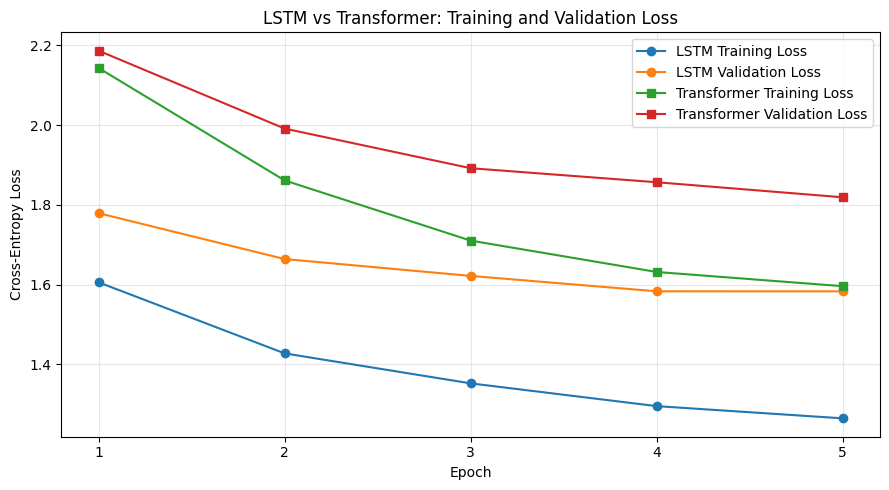

In [29]:
# Reconstruct LSTM history from the recorded training output.
lstm_history_df = pd.DataFrame({
    "epoch": [1, 2, 3, 4, 5],
    "train_loss": [1.6058, 1.4276, 1.3524, 1.2953, 1.2647],
    "val_loss": [1.7792, 1.6642, 1.6219, 1.5833, 1.5832]
})

# Use the saved Transformer training history.
transformer_history_df = pd.DataFrame(transformer_history)

# Plot training and validation losses.
plt.figure(figsize=(9, 5))

plt.plot(lstm_history_df["epoch"], lstm_history_df["train_loss"],
         marker="o", label="LSTM Training Loss")
plt.plot(lstm_history_df["epoch"], lstm_history_df["val_loss"],
         marker="o", label="LSTM Validation Loss")

plt.plot(transformer_history_df["epoch"], transformer_history_df["train_loss"],
         marker="s", label="Transformer Training Loss")
plt.plot(transformer_history_df["epoch"], transformer_history_df["val_loss"],
         marker="s", label="Transformer Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("LSTM vs Transformer: Training and Validation Loss")
plt.xticks(range(1, 6))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.3 Quantitative Results Interpretation

The LSTM achieved the lowest validation loss (1.5671), outperforming the Transformer (1.8096) and Bigram model (2.4996). This indicates that the LSTM captured useful sequential patterns more effectively under the selected experimental settings.

The Transformer trained faster than the LSTM, taking 45.55 seconds compared with 65.78 seconds. However, its validation loss remained higher after five epochs. Both neural models showed decreasing training and validation losses, suggesting effective learning without clear evidence of severe overfitting.

The Bigram model was computationally inexpensive to construct but had limited predictive performance because it considers only the immediately preceding character rather than a longer context.

### 5.4 Qualitative Comparison of Generated Text

The generated samples are evaluated qualitatively based on word formation, grammatical structure, character-level patterns, dialogue consistency, and overall readability.

All three models use the same initial prompt and generation length, allowing their outputs to be compared under similar conditions.

In [34]:
# Generate text using the same starting prompt and length.

bigram_generated_text = generate_bigram(
    start_text="ROMEO:",
    max_new_tokens=500
)

lstm_generated_text = generate_lstm(
    start_text="ROMEO:",
    max_new_tokens=500,
    temperature=0.8
)

print("=" * 70)
print("BIGRAM GENERATED TEXT")
print("=" * 70)
print(bigram_generated_text)

print("\n" + "=" * 70)
print("LSTM GENERATED TEXT")
print("=" * 70)
print(lstm_generated_text)

print("\n" + "=" * 70)
print("TRANSFORMER GENERATED TEXT")
print("=" * 70)
print(transformer_generated_text)

BIGRAM GENERATED TEXT
ROMEO:
Climagomour wedvis I n od y hauDY f bamith Bethatheve,
S:
METhe rom the fe
Hando in urveimomaneranthe hthtend t:
Cos, t Wh atayono shifay asisuloorend t wanghedve
ANoma herencunemys bl o kXFin fanconys grs ntellf II d ate.
CAl h,

Qn s tir tith rtithareve ccurs, horarand bulcoowere I aroue farorenifor
IIS: ntak.
USthe or highis,
Bo nn-'t eve.
Coveswh hen hidisty atimes Hepoth hat cho, tl onemasour herorker d a VICher tharare thatheeth mirullewend.
DUMusy nd norit y; an:
ARCEnd ly w towitha har 

LSTM GENERATED TEXT
ROMEO:
I have mend the peace sing come of love
That thou art shall be bohthy to thy heapts,
That thou shalt cry lived him purse, be well
The month must addich yet with present.

MERCUTIO:
Nay, nor grief, all I shall be this cheeks,
Gresson and many thought of death, my lord.

FRIAR LAURENCE:
Ay, well, looks her met
That fear, if you may take your soldiers have
Whom so sure you honour may be not.

CAMILLO:
Yes, I did show me to thy blood is accust

### 5.5 Qualitative Results and Interpretation

The generated samples reveal clear differences in language quality across the three models. The Bigram model produced mostly fragmented character sequences with very limited word formation. Its reliance on only the preceding character restricted its ability to capture broader linguistic patterns.

The LSTM generated more recognizable words, dialogue structures, and grammatically plausible sentences. It demonstrated a stronger ability to learn sequential dependencies and maintain contextual patterns.

The Transformer generated recognizable character names, dialogue formatting, and Shakespeare-like expressions. However, its output contained malformed words and inconsistent sentence structures. Despite its ability to model relationships across the context window through self-attention, its performance remained below the LSTM in this experiment.

Overall, the LSTM produced the most coherent text, followed by the Transformer and then the Bigram model. These observations are consistent with the validation loss results.

### 5.6 Computational Efficiency and Model Complexity

Computational efficiency is evaluated using model size and execution time. The number of trainable parameters indicates the model's capacity, while execution time provides an indication of computational cost.

The Bigram model uses a transition-count matrix rather than gradient-based training. Therefore, its construction time is reported separately and should not be interpreted as directly equivalent to neural network training time.

In [35]:
# Calculate trainable parameter counts.
lstm_parameters = sum(
    p.numel() for p in lstm_model.parameters()
    if p.requires_grad
)

transformer_parameters = sum(
    p.numel() for p in transformer_model.parameters()
    if p.requires_grad
)

# Bigram uses a 65 x 65 transition probability matrix.
bigram_parameters = bigram_probs.numel()

complexity_df = pd.DataFrame([
    {
        "Model": "Bigram",
        "Parameters / Entries": bigram_parameters,
        "Execution Time (seconds)": 0.1043,
        "Time Type": "Construction"
    },
    {
        "Model": "LSTM",
        "Parameters / Entries": lstm_parameters,
        "Execution Time (seconds)": 65.78,
        "Time Type": "Training"
    },
    {
        "Model": "Transformer",
        "Parameters / Entries": transformer_parameters,
        "Execution Time (seconds)": 45.55,
        "Time Type": "Training"
    }
])

print("MODEL COMPLEXITY AND EXECUTION TIME")
print("=" * 85)
print(complexity_df.to_string(index=False))

MODEL COMPLEXITY AND EXECUTION TIME
      Model  Parameters / Entries  Execution Time (seconds)    Time Type
     Bigram                  4225                    0.1043 Construction
       LSTM                946625                   65.7800     Training
Transformer                429889                   45.5500     Training


The Bigram model has the smallest representation, with 4,225 transition entries, and the shortest construction time (0.1043 seconds). However, its simplicity comes with limited predictive capability.

The LSTM has 946,625 trainable parameters, making it the largest neural model in this experiment. It achieved the lowest validation loss but required 65.78 seconds to train.

The Transformer has 429,889 trainable parameters, fewer than the LSTM, and completed training in 45.55 seconds. Although it was faster and more compact than the LSTM, its validation loss was higher.

These results illustrate the trade-off between model complexity, computational cost, and predictive performance.

# Part 6: Conclusion and Reflection

### 6.1 Summary of Results

In this experiment, three character-based language models were tested: Bigram, LSTM, and Transformer on the Tiny Shakespeare dataset.

The Bigram model served as a simple benchmark but failed to produce coherent text since it was able to look back only one character behind. The LSTM showed the best results in terms of prediction and produced the most coherent Shakespeare-like text, with a validation loss of 1.5671. The Transformer model had a validation loss of 1.8096 and trained faster than the LSTM.

### 6.2 Why Are Transformers Powerful?

Transformers are powerful due to the self-attention mechanism as it allows modeling relationships between different positions in a sequence explicitly. Unlike other models, for instance, LSTMs that consider tokens one-by-one, Transformers can handle processing of sequence positions in parallel during training.

The multi-head attention mechanism allows the model to learn various kinds of relationships simultaneously, whereas positional embeddings bring information about token order into the model architecture. This approach is also scalable enough for handling big datasets and model size.

Thus, Transformers can capture long-term dependencies and benefit from large-scale pretraining, which is why they became a basis for modern large language models.

However, the effectiveness of Transformer largely depends on many different aspects like, for instance, size of the model itself, size and quality of training data, computational resources, and parameters of the training procedure. In the current experiment, the performance of LSTM was higher for the chosen training setup.

### 6.3 Limitations and Further Enhancements

There are some limitations to this experiment. The first limitation is that the models have been trained for five epochs only, which can be increased in future work. Another limitation is the use of smaller architectures of the Transformer and LSTM models and small datasets to train them. These limitations can affect the outcome of the models as they might perform differently with large datasets and more training epochs.

Another limitation of this experiment is the use of sampled batches for calculating loss functions and checking the generated text qualitatively. In future work, the use of fixed batches for evaluation and using more measures such as perplexity can be considered.

### 6.4 Final Reflection

This project illustrated how various language modeling architectures pick up on character level patterns. The Bigram architecture served as a simple baseline model, whereas the LSTM proved the importance of recurrent memories in capturing sequential relationships. Lastly, the Transformer proved that self-attention could model contextual relationships in the absence of sequential recurrence.

One key insight gained from this project was that the LSTM performed better than the Transformer in this particular experiment, although this is contrary to the current trend where Transformer models dominate the state-of-the-art in NLP applications.

In summary, this project improved my comprehension of language modeling, architectures of neural networks, training processes, and model evaluations.